# PathSnap – 01 Datapreprossing and EDA 
Short exploratory analysis of the GPS tracks, road networks and reference routes. Every table and plot is split by **partition** (train / student_test). All distances are in metres (UTM).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx, folium, shapely
from src.data_prep import DATA, PARTITIONS, list_trips, load_trip, project_trip, arc_lines
FIG, MAPS = ROOT / 'reports/figures', ROOT / 'reports/maps'
FIG.mkdir(parents=True, exist_ok=True); MAPS.mkdir(parents=True, exist_ok=True)
dq = pd.read_csv(ROOT / 'results/data_quality.csv', dtype={'trip_id': str})
pts = pd.read_parquet(ROOT / 'processed/points_labelled.parquet')
sweep = pd.read_csv(ROOT / 'results/radius_sweep.csv')

## 1. Inventory: trips, row counts, file sizes

In [2]:
rows = []
for part in PARTITIONS:
    for d in list_trips(part):
        for f in d.iterdir():
            rows.append({'partition': part, 'trip_id': d.name, 'file': f.suffix[1:], 'MB': f.stat().st_size / 1e6})
files = pd.DataFrame(rows)
inv = files.pivot_table(index='partition', columns='file', values='MB', aggfunc='sum').round(1)
inv.insert(0, 'n_trips', files.groupby('partition')['trip_id'].nunique())
print('Total size (MB) per file type:'); display(inv)
display(dq.groupby('partition')[['n_points', 'n_nodes', 'n_arcs', 'n_route_arcs']].sum())

Total size (MB) per file type:


file,n_trips,arcs,nodes,route,track
partition,,,,,
student_test,10,1.9,1.8,0.0,0.6
train,80,44.3,38.4,0.2,6.9


,n_points,n_nodes,n_arcs,n_route_arcs
partition,,,,
student_test,19160,90689,185041,3477
train,208417,1933485,3876904,31336


## 2. Points per trip, sampling intervals, gaps, anomaly trips

In [3]:
display(dq.groupby('partition')[['n_points', 'median_dt_s', 'max_gap_s', 'n_gaps_gt_10s']].describe().T.round(1))
pts['dt'] = pts.groupby(['partition', 'trip_id'])['timestamp'].diff()
print('Sampling interval (s) value counts, top 5:')
display(pts.groupby('partition')['dt'].value_counts().groupby(level=0).head(5))
print('Largest gaps:')
display(dq.nlargest(5, 'max_gap_s')[['partition', 'trip_id', 'n_points', 'max_gap_s', 'n_gaps_gt_10s']])

partition            student_test     train
n_points      count          10.0      80.0
              mean         1916.0    2605.2
              std          1335.4    3312.3
              min           262.0     361.0
              25%           917.8     945.8
              50%          1420.0    1529.0
              75%          2872.0    2792.8
              max          3958.0   19313.0
median_dt_s   count          10.0      80.0
              mean            1.0       1.0
              std             0.0       0.0
              min             1.0       1.0
              25%             1.0       1.0
              50%             1.0       1.0
              75%             1.0       1.0
              max             1.0       1.0
max_gap_s     count          10.0      80.0
              mean           25.5    2706.4
              std            65.5   18017.4
              min             1.0       1.0
              25%             1.0       1.8
              50%             2.0      11.0
              75%             2.8      73.8
              max           210.0  153064.0
n_gaps_gt_10s count          10.0      80.0
              mean            2.7       7.4
              std             7.5      26.3
              min             0.0       0.0
              25%             0.0       0.0
              50%             0.0       0.5
              75%             0.0       5.0
              max            24.0     215.0

Sampling interval (s) value counts, top 5:


partition     dt  
student_test  1.0      18886
              2.0        126
              3.0         62
              4.0         28
              11.0         9
train         1.0     201048
              2.0       4335
              3.0       1061
              4.0        407
              5.0        252
Name: count, dtype: int64

Largest gaps:


,partition,trip_id,n_points,max_gap_s,n_gaps_gt_10s
72,train,00000090,536,153064.0,6
61,train,00000078,2909,52810.0,25
55,train,00000069,2067,2658.0,2
16,train,00000021,15783,2161.0,2
8,train,00000011,2828,909.0,1


In [4]:
checks = ['timestamps_sorted', 'lonlat_in_range', 'arc_nodes_in_range', 'route_ids_in_range']
anom = dq[(~dq[checks].all(axis=1)) | (dq['nan_values'] > 0) | (dq['duplicate_timestamps'] > 0)
          | (dq['n_gaps_gt_10s'] > 0) | (dq['label_uncertain_frac'] > 0.05)]
print(f'{len(anom)} anomaly trips (any failed check, gaps > 10 s, or > 5% uncertain labels):')
display(anom[['partition', 'trip_id', 'n_points', 'duplicate_timestamps', 'duplicate_points', 'n_gaps_gt_10s',
              'max_gap_s', 'route_breaks', 'label_uncertain_frac']])

48 anomaly trips (any failed check, gaps > 10 s, or > 5% uncertain labels):


,partition,trip_id,n_points,duplicate_timestamps,duplicate_points,n_gaps_gt_10s,max_gap_s,route_breaks,label_uncertain_frac
0,train,00000001,1315,0,0,1,16.0,0,0.000000
1,train,00000002,7243,0,2,41,160.0,1,0.120392
3,train,00000004,1064,0,0,215,51.0,0,0.001880
5,train,00000006,1450,0,0,5,301.0,0,0.000000
6,train,00000008,3093,0,2,0,2.0,0,0.144197
8,train,00000011,2828,0,0,1,909.0,0,0.000000
11,train,00000014,448,0,0,5,72.0,0,0.000000
16,train,00000021,15783,0,12,2,2161.0,0,0.001204
17,train,00000022,474,0,0,9,22.0,0,0.000000
18,train,00000024,801,0,0,2,458.0,0,0.000000


## 3. Road networks: nodes, arcs, connected components

In [5]:
net = []
for part in PARTITIONS:
    for d in list_trips(part):
        tr = load_trip(d)
        G = nx.DiGraph(); G.add_edges_from(tr['arcs'].itertuples(index=False, name=None))
        comps = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
        net.append({'partition': part, 'trip_id': d.name, 'nodes': len(tr['nodes']), 'arcs': len(tr['arcs']),
                    'weak_components': len(comps), 'largest_comp_frac': comps[0] / G.number_of_nodes(),
                    'strong_components': nx.number_strongly_connected_components(G)})
net = pd.DataFrame(net)
display(net.groupby('partition')[['nodes', 'arcs', 'weak_components', 'largest_comp_frac', 'strong_components']].describe().T.round(3))

partition                student_test       train
nodes             count        10.000      80.000
                  mean       9068.900   24168.562
                  std        7452.176   32272.296
                  min        1770.000     299.000
                  25%        4908.000    3487.750
                  50%        6596.500    9608.000
                  75%       11844.250   28846.750
                  max       26635.000  155003.000
arcs              count        10.000      80.000
                  mean      18504.100   48461.300
                  std       15496.930   64738.837
                  min        3577.000     649.000
                  25%       10292.250    7061.750
                  50%       13145.000   19526.500
                  75%       24818.500   58003.250
                  max       56027.000  307392.000
weak_components   count        10.000      80.000
                  mean         22.700      39.012
                  std          29.182      60.682
                  min           5.000       1.000
                  25%           7.250       9.750
                  50%          11.000      20.000
                  75%          21.750      42.250
                  max         100.000     421.000
largest_comp_frac count        10.000      80.000
                  mean          0.964       0.969
                  std           0.034       0.039
                  min           0.874       0.693
                  25%           0.964       0.963
                  50%           0.971       0.981
                  75%           0.983       0.987
                  max           0.991       1.000
strong_components count        10.000      80.000
                  mean         97.400     250.475
                  std         125.957     343.237
                  min           6.000       2.000
                  25%          21.750      15.500
                  50%          53.500     127.000
                  75%          94.750     328.500
                  max         415.000    1942.000

## 4. Route length and connectivity breaks

In [6]:
rl = []
for part in PARTITIONS:
    for d in list_trips(part):
        tr = project_trip(load_trip(d)); lines = arc_lines(tr)
        rl.append({'partition': part, 'trip_id': d.name, 'route_km': shapely.length(lines[tr['route']]).sum() / 1000,
                   'track_km': np.hypot(np.diff(tr['track']['x']), np.diff(tr['track']['y'])).sum() / 1000})
rl = pd.DataFrame(rl).merge(dq[['trip_id', 'partition', 'route_breaks', 'route_repeated_arcs']])
rl['track_over_route'] = rl['track_km'] / rl['route_km']
display(rl.groupby('partition')[['route_km', 'track_km', 'track_over_route', 'route_breaks', 'route_repeated_arcs']].describe().T.round(2))
print('Trips with route breaks:'); display(rl[rl['route_breaks'] > 0])

partition                  student_test   train
route_km            count         10.00   80.00
                    mean          24.81   27.86
                    std           21.26   25.71
                    min            5.29    5.01
                    25%            9.87    8.93
                    50%           14.76   14.31
                    75%           40.26   39.40
                    max           64.81   94.34
track_km            count         10.00   80.00
                    mean          29.75   37.27
                    std           22.87   34.52
                    min            5.56    6.34
                    25%           12.18   12.80
                    50%           20.96   24.05
                    75%           48.50   48.80
                    max           71.78  169.55
track_over_route    count         10.00   80.00
                    mean           1.27    1.53
                    std            0.36    1.10
                    min            1.05    1.01
                    25%            1.11    1.08
                    50%            1.15    1.18
                    75%            1.25    1.46
                    max            2.27    7.50
route_breaks        count         10.00   80.00
                    mean           0.10    0.16
                    std            0.32    0.49
                    min            0.00    0.00
                    25%            0.00    0.00
                    50%            0.00    0.00
                    75%            0.00    0.00
                    max            1.00    3.00
route_repeated_arcs count         10.00   80.00
                    mean          25.50    0.84
                    std           80.64    3.77
                    min            0.00    0.00
                    25%            0.00    0.00
                    50%            0.00    0.00
                    75%            0.00    0.00
                    max          255.00   29.00

Trips with route breaks:


,partition,trip_id,route_km,track_km,route_breaks,route_repeated_arcs,track_over_route
1,train,00000002,7.973523,55.944589,1,0,7.016295
14,train,00000019,42.760111,48.797549,3,0,1.141193
26,train,00000033,6.385711,47.909111,1,0,7.502549
33,train,00000041,12.588008,14.517712,1,0,1.153297
34,train,00000042,80.261288,97.857858,1,0,1.219241
55,train,00000069,19.354243,25.774888,1,29,1.331744
60,train,00000075,6.449537,13.410412,2,2,2.079283
63,train,00000080,12.374188,23.637789,1,0,1.910250
69,train,00000086,78.311633,83.961327,1,2,1.072144
71,train,00000089,11.311245,14.645341,1,0,1.294759


## 5. Plots (saved to reports/figures/)

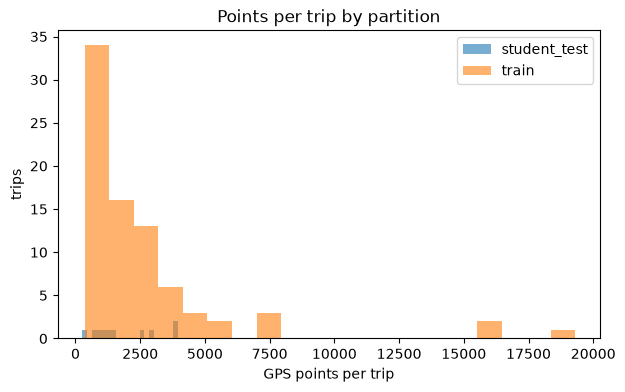

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for part, g in dq.groupby('partition'):
    ax.hist(g['n_points'], bins=20, alpha=0.6, label=part)
ax.set(xlabel='GPS points per trip', ylabel='trips', title='Points per trip by partition'); ax.legend()
fig.savefig(FIG / '01_points_per_trip.png', dpi=120, bbox_inches='tight'); plt.show()

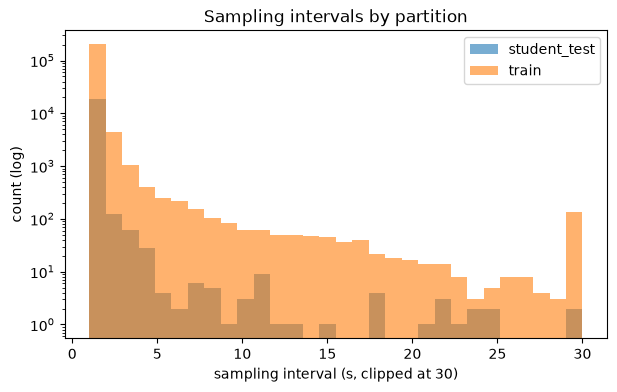

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for part, g in pts.groupby('partition'):
    ax.hist(g['dt'].dropna().clip(upper=30), bins=30, alpha=0.6, label=part, log=True)
ax.set(xlabel='sampling interval (s, clipped at 30)', ylabel='count (log)', title='Sampling intervals by partition'); ax.legend()
fig.savefig(FIG / '02_sampling_intervals.png', dpi=120, bbox_inches='tight'); plt.show()

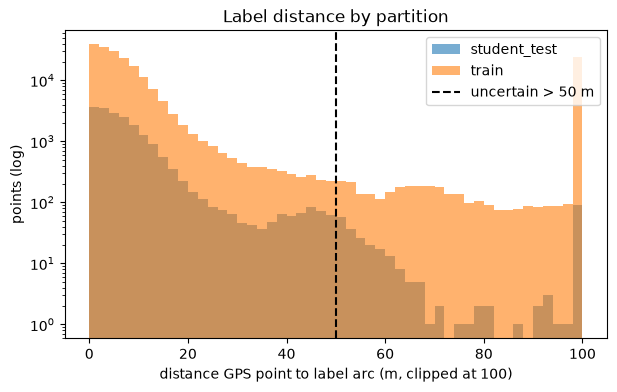

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for part, g in pts.groupby('partition'):
    ax.hist(g['label_dist'].clip(upper=100), bins=50, alpha=0.6, label=part, log=True)
ax.axvline(50, color='k', ls='--', label='uncertain > 50 m')
ax.set(xlabel='distance GPS point to label arc (m, clipped at 100)', ylabel='points (log)', title='Label distance by partition'); ax.legend()
fig.savefig(FIG / '03_label_distance.png', dpi=120, bbox_inches='tight'); plt.show()

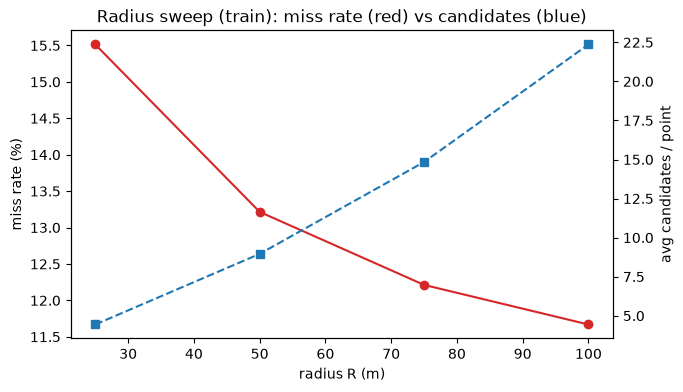

In [10]:
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(sweep['radius_m'], sweep['miss_rate'] * 100, 'o-', color='tab:red'); ax1.set(xlabel='radius R (m)', ylabel='miss rate (%)')
ax2 = ax1.twinx(); ax2.plot(sweep['radius_m'], sweep['avg_candidates_per_point'], 's--', color='tab:blue'); ax2.set_ylabel('avg candidates / point')
ax1.set_title('Radius sweep (train): miss rate (red) vs candidates (blue)')
fig.savefig(FIG / '04_radius_sweep.png', dpi=120, bbox_inches='tight'); plt.show()

## 6. Folium map of one train trip (saved to reports/maps/)

In [11]:
tid = list_trips('train')[0].name
tr = project_trip(load_trip(DATA / 'train' / tid)); lines = arc_lines(tr)
track_line = shapely.linestrings(tr['track'][['x', 'y']].to_numpy())
near = shapely.STRtree(lines).query(track_line, predicate='dwithin', distance=150)  # only arcs near the track
nodes = tr['nodes'][['lat', 'lon']].to_numpy(); arcs = tr['arcs'].to_numpy()
m = folium.Map(location=tr['track'][['lat', 'lon']].mean().tolist(), zoom_start=14, tiles="OpenStreetMap")
fg_net, fg_route, fg_gps = (folium.FeatureGroup(name=n) for n in ['Road network (within 150 m)', 'Reference route', 'GPS points'])
for a in near:
    folium.PolyLine(nodes[arcs[a]].tolist(), color='gray', weight=1).add_to(fg_net)
for a in tr['route']:
    folium.PolyLine(nodes[arcs[a]].tolist(), color='blue', weight=4).add_to(fg_route)
for lat, lon, unc in tr['track'].assign(u=pts.query('trip_id == @tid')['label_uncertain'].to_numpy())[['lat', 'lon', 'u']].itertuples(index=False):
    folium.CircleMarker([lat, lon], radius=2, color='red' if unc else 'orange', fill=True).add_to(fg_gps)
for fg in (fg_net, fg_route, fg_gps): fg.add_to(m)
folium.LayerControl().add_to(m)
legend = ('<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px;border:1px solid grey;font-size:13px">'
          f'<b>Trip {tid}</b><br><span style="color:gray">&#9644;</span> road network<br><span style="color:blue">&#9644;</span> reference route<br>'
          '<span style="color:orange">&#9679;</span> GPS point<br><span style="color:red">&#9679;</span> uncertain label (&gt;50 m)</div>')
m.get_root().html.add_child(folium.Element(legend))
m.save(str(MAPS / f'trip_{tid}.html')); print('saved', MAPS / f'trip_{tid}.html')

saved D:\SEM FILES\SEM5\ML\HACKATHON\Pathsnap-team-09\reports\maps\trip_00000001.html


## 7. Data issues and decisions

In [12]:
print('Label quality by partition:')
display(pts.groupby('partition').agg(points=('label', 'size'), median_label_dist_m=('label_dist', 'median'),
        p95_label_dist_m=('label_dist', lambda s: s.quantile(0.95)), uncertain_frac=('label_uncertain', 'mean')).round(3))

Label quality by partition:


,points,median_label_dist_m,p95_label_dist_m,uncertain_frac
partition,,,,
student_test,19160,5.592,27.472,0.015
train,208417,5.956,169.260,0.132


**Data issues found (real numbers from `results/data_quality.csv`)**
- No NaNs, no unsorted timestamps, no duplicate timestamps, all lon/lat in range, all arc node ids and route arc ids in range (both partitions).
- Duplicate GPS positions: 572 in train and 6 in student_test. These are stationary points and I keep them.
- Time gaps > 10 s: 40 of 80 train trips (590 gaps) and 2 of 10 test trips (27 gaps). The largest gaps are 153,064 s (~42 h, train 00000090) and 52,810 s (train 00000078), so some tracks contain several recordings.
- Route connectivity breaks (consecutive route arcs that don't share a node): 13 in 10 train trips and 1 in 1 test trip.
- Repeated arcs in the route (loops or U-turns): 67 in train, 255 in test (mostly test 00000056).
- Network sizes vary a lot, up to 307,392 arcs in one trip.
- Label quality: the median label distance is ~6 m, but 13.2% of train points are uncertain (> 50 m). Most of these come from trip 00000054 (89% uncertain, median 146 m from any route arc), whose reference route doesn't cover most of its GPS track. Trips 00000034 and 00000093 are cases where the forward pointer fell behind (the points are within 5 m of a later route arc).
- Trips span 25 UTM zones, 3 of them in the southern hemisphere.

**Decisions**
- Each trip is projected to its own UTM zone, so all distances are true metres.
- Bad points are not dropped. Points > 50 m from their label arc are flagged `label_uncertain` so the model step can filter or down-weight them.
- Candidates are queried once at 100 m and filtered to 25/50/75. R = 75 m was chosen: it is the smallest radius whose miss rate is within 1 percentage point of R = 100 m (12.2% vs 11.7%) while giving 34% fewer candidates (14.8 vs 22.4 per point).
- Before building the STRtree, arcs are pre-filtered to the track bounding box + 150 m (for speed).